# G04 - Hal Fiyatlarıyla Akıllı Satın Alma: Yapay Zekâ ve Tahmin Modelleri (`03_model.ipynb`)

Bu notebook, **B Kişisi (Yapay Zekâ ve Tahmin)** görev listesindeki **13 adımı** eksiksiz olarak uygular ve ek olarak **1 Haftalık (`t+7`) + 1 Aylık (`t+30` / 4 Haftalık)** çok ufuklu fiyat tahmini ve karar desteği üretir:
- **Adım 1:** Veriyi okuma (`hal_reel_ozellikli.csv`), `TARIH` dönüşümü, `İTHAL..` $\rightarrow$ `ITHAL` standardizasyonu, kronolojik sıralama, `df.head()`, `df.shape`, `df.info()` ve **ardışık tarihler arasındaki gün farkı kontrolü**.
- **Adım 2 (Görev A – Ürünleri Kümeleme):** `ilk_25_aylik_reel_fiyat.csv` ile 12 aylık mevsimsel fiyat tablosu, ürün ortalamasına bölerek normalize etme, `Pipeline([("olcek", StandardScaler()), ("kmeans", KMeans(...))])`, $k=3$ ve $k=4$ için **Silhouette Skoru** + **Dirsek (Elbow) Grafiği**, veriye dayalı küme adlandırması ve `01_Veri/urun_kumeleri.csv` kaydı.
- **Adım 3 & 4 (Görev B – Hedef ve Girdiler):** `HEDEF` (1 Hafta / 7 kayıt sonrası) ve `HEDEF_AYLIK` (1 Ay / 30 kayıt sonrası) hedeflerinin oluşturulması; `MAL_ADI, MAL_TURU, BIRIM, AY, HAFTA, REEL_ORTALAMA_UCRET, REEL_LAG_1, REEL_LAG_7, REEL_LAG_30, REEL_DEGISIM_YUZDE, REEL_OYNAKLIK_7, REEL_OYNAKLIK_30` girdilerinin seçimi, `inf` ve `NaN` temizliği.
- **Adım 5 & 6 (Eğitim/Test Ayrımı ve Pipeline):** Kronolojik **%80 Eğitim – %20 Test** ayrımı, eğitim kümesinin test başlangıcından **7 gün önce bitirilmesi (veri sızıntısı önlemi)** ve `ColumnTransformer(OneHotEncoder + StandardScaler)` + `Pipeline`.
- **Adım 7, 8 & 9 (3 Model Karşılaştırması, Hiperparametre Denemesi ve Model Seçimi):** **Naif Baseline**, **Random Forest** ve **Gradient Boosting** modellerinin `TimeSeriesSplit(n_splits=5)` ile karşılaştırılması (`MAE, RMSE, MAPE, R²`), hiperparametre araması (`RandomizedSearchCV`) ve **Fiyat Değişim Oranı (`HEDEF / REEL_ORTALAMA_UCRET`) yaklaşımıyla Naif Baseline modelin geçilmesi**.
- **Adım 10 & 11 (Özellik Önemi, SHAP ve Kayıtlar):** One-Hot sütunlarının orijinal değişken adında toplanması (`01_Veri/ozellik_onemi.csv`), **SHAP `summary_plot` (+3 ekstra puan)**, `01_Veri/model_karsilastirma.csv`, `03_Model/model.joblib` (haftalık) ve `03_Model/model_aylik.joblib` (1 aylık) kayıtları.
- **Adım 12 & 13 (`tahmin_et(urun, tarih)` ve Teslim):** Hem **1 Haftalık** hem **1 Aylık (Hafta 1, Hafta 2, Hafta 3, Hafta 4 / 1 Ay)** tahmin, belirsizlik aralığı ($\pm \text{MAE}$) ve `%5` eşiğine göre **"ŞİMDİ AL / BEKLE"** kararı üreten fonksiyon ve `scikit-learn` sürüm kontrolü.

## Adım 1 – Veriyi Oku, Temizle ve Ardışık Gün Farklarını Kontrol Et

In [1]:
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120

def proje_koku_bul(baslangic: Path = Path.cwd()) -> Path:
    for aday in [baslangic] + list(baslangic.parents):
        if (aday / "01_Veri").exists() and (aday / "03_Model").exists():
            return aday
    return baslangic

PROJE_KOKU = proje_koku_bul()
VERI_KLASORU = PROJE_KOKU / "01_Veri"
MODEL_KLASORU = PROJE_KOKU / "03_Model"
RAPOR_KLASORU = PROJE_KOKU / "04_Rapor"
MODEL_KLASORU.mkdir(parents=True, exist_ok=True)
RAPOR_KLASORU.mkdir(parents=True, exist_ok=True)

def mal_turu_standartlastir(deger: str) -> str:
    s = str(deger).strip().upper()
    s = re.sub(r"\s+", " ", s)
    s_norm = s.replace("İ", "I").strip(".")
    if s_norm.startswith("ITHAL"):
        return "ITHAL"
    return s.strip(".")

def metin_standartlastir(seri: pd.Series) -> pd.Series:
    return (
        seri.astype(str)
        .str.strip()
        .str.upper()
        .str.replace(r"\s+", " ", regex=True)
    )

# 1.1 hal_reel_ozellikli.csv'yi oku, TARIH'i datetime yap, ITHAL standardizasyonu uygula ve tarihe göre sırala
df = pd.read_csv(VERI_KLASORU / "hal_reel_ozellikli.csv", low_memory=False)
df["TARIH"] = pd.to_datetime(df["TARIH"], errors="coerce")
df["MAL_TURU"] = df["MAL_TURU"].apply(mal_turu_standartlastir)
df["MAL_ADI"] = metin_standartlastir(df["MAL_ADI"])
df["BIRIM"] = metin_standartlastir(df["BIRIM"])

# Kronolojik sıralama (sonraki tüm adımlar zaman sırasına bağlıdır)
df = df.sort_values(["MAL_ADI", "BIRIM", "TARIH"]).reset_index(drop=True)

print("=== 1. VERİ BOYUTU (df.shape) ===")
print("Satır ve Sütun Sayısı:", df.shape)
print(f"Tarih Aralığı: {df['TARIH'].min().date()} -> {df['TARIH'].max().date()} ({df['YIL'].nunique()} yıl)")
print(f"Benzersiz Ürün Sayısı: {df['MAL_ADI'].nunique()} ürün")
print("Standartlaştırılmış MAL_TURU Dağılımı:", df["MAL_TURU"].value_counts().to_dict())

print("\n=== 2. İLK 5 SATIR (df.head()) ===")
print(df[["TARIH", "MAL_TURU", "MAL_ADI", "BIRIM", "ORTALAMA_UCRET", "REEL_ORTALAMA_UCRET", "REEL_LAG_1", "REEL_LAG_7"]].head())

print("\n=== 3. VERİ BİLGİSİ (df.info()) VE EKSİK DEĞER KONTROLÜ ===")
df.info()
print("\nSütun Bazlı Boş (NaN) Değer Sayıları:\n", df.isna().sum())

# 1.2 KONTROL: Kayıtlar günlük mü? Ardışık tarihler arasındaki gün farkı analizi
df["GUN_FARKI"] = df.groupby(["MAL_ADI", "BIRIM"])["TARIH"].diff().dt.days
fark_dagilimi = df["GUN_FARKI"].value_counts().head(5).to_dict()
ort_7_kayit_gun = df.groupby(["MAL_ADI", "BIRIM"])["TARIH"].transform(lambda s: (s.shift(-7) - s).dt.days).median()
ort_30_kayit_gun = df.groupby(["MAL_ADI", "BIRIM"])["TARIH"].transform(lambda s: (s.shift(-30) - s).dt.days).median()

print("\n=== 4. ARDIŞIK TARİHLER ARASINDAKİ GÜN FARKI KONTROLÜ (RAPOR NOTU) ===")
print("Ardışık iki kayıt arasındaki gün farkı dağılımı (İlk 5):", fark_dagilimi)
print(f"- NOT: Hal hafta sonları (Cumartesi-Pazar) ve resmi tatillerde kapalı olduğu için ardışık kayıtların %{ (df['GUN_FARKI']==1).mean()*100:.1f}'i 1 gün, %{(df['GUN_FARKI']==3).mean()*100:.1f}'ü 3 gün (Cuma->Pazartesi) aralıklıdır.")
print(f"- Bu nedenle '7 kayıt sonrası (shift(-7))' medyan olarak {ort_7_kayit_gun:.0f} takvim gününe (yaklaşık 1.5 hafta / 7 iş günü), '30 kayıt sonrası (shift(-30))' ise medyan olarak {ort_30_kayit_gun:.0f} takvim gününe (yaklaşık 6 hafta / 30 iş günü) karşılık gelmektedir. Bu durum A kişisine ve raporun sınırlılıklar bölümüne not edilmiştir.")

=== 1. VERİ BOYUTU (df.shape) ===
Satır ve Sütun Sayısı: (131888, 18)
Tarih Aralığı: 2006-01-02 -> 2024-12-31 (19 yıl)
Benzersiz Ürün Sayısı: 25 ürün
Standartlaştırılmış MAL_TURU Dağılımı: {'SEBZE': 95238, 'MEYVE': 20878, 'ITHAL': 15772}

=== 2. İLK 5 SATIR (df.head()) ===
       TARIH MAL_TURU MAL_ADI BIRIM  ORTALAMA_UCRET  REEL_ORTALAMA_UCRET  \
0 2006-01-02    ITHAL  ANANAS  ADET             4.0                 86.9   
1 2006-01-03    ITHAL  ANANAS  ADET             4.0                 86.9   
2 2006-01-04    ITHAL  ANANAS  ADET             4.0                 86.9   
3 2006-01-05    ITHAL  ANANAS  ADET             4.0                 86.9   
4 2006-01-06    ITHAL  ANANAS  ADET             4.0                 86.9   

   REEL_LAG_1  REEL_LAG_7  
0         NaN         NaN  
1        86.9         NaN  
2        86.9         NaN  
3        86.9         NaN  
4        86.9         NaN  

=== 3. VERİ BİLGİSİ (df.info()) VE EKSİK DEĞER KONTROLÜ ===
<class 'pandas.DataFrame'>
RangeIndex: 1


=== 4. ARDIŞIK TARİHLER ARASINDAKİ GÜN FARKI KONTROLÜ (RAPOR NOTU) ===
Ardışık iki kayıt arasındaki gün farkı dağılımı (İlk 5): {1.0: 106485, 2.0: 13098, 3.0: 11017, 4.0: 667, 5.0: 322}
- NOT: Hal hafta sonları (Cumartesi-Pazar) ve resmi tatillerde kapalı olduğu için ardışık kayıtların %80.7'i 1 gün, %8.4'ü 3 gün (Cuma->Pazartesi) aralıklıdır.
- Bu nedenle '7 kayıt sonrası (shift(-7))' medyan olarak 9 takvim gününe (yaklaşık 1.5 hafta / 7 iş günü), '30 kayıt sonrası (shift(-30))' ise medyan olarak 38 takvim gününe (yaklaşık 6 hafta / 30 iş günü) karşılık gelmektedir. Bu durum A kişisine ve raporun sınırlılıklar bölümüne not edilmiştir.


## Adım 2 – Görev A: Ürünleri Mevsimsellik Şekline Göre Kümele (`K-Means`)

- `01_Veri/ilk_25_aylik_reel_fiyat.csv` dosyasından her ürün için **12 sütunlu (Ocak...Aralık)** tablo hazırlanır.
- Fiyat seviyeleri farklı olduğu için her ürün kendi yıllık ortalamasına bölünür (`mevsim_sekli`); böylece yalnızca **mevsimsel dalgalanma şekli** karşılaştırılır.
- `Pipeline([("olcek", StandardScaler()), ("kmeans", KMeans(...))])` kurulur; $k=3$ ve $k=4$ için **Silhouette Skoru** hesaplanır ve **Dirsek (Elbow)** grafiği çizilir.
- Sonuçlar `MAL_ADI, KUME_NO, KUME_ADI` sütunlarıyla **`01_Veri/urun_kumeleri.csv`** (ve yedek olarak `03_Model/urun_mevsimsel_kumeler.csv`) olarak kaydedilir.

k=3 Silhouette Skoru: 0.4120
k=4 Silhouette Skoru: 0.4334
>>> Seçilen Optimal Küme Sayısı: k = 4 (Silhouette = 0.4334)

=== 01_Veri/urun_kumeleri.csv KAYDEDİLDİ ===
       MAL_ADI  KUME_NO                                                                       KUME_ADI EN_UCUZ_AY EN_PAHALI_AY  MEVSIMSEL_GENLIK_ORAN
        ANANAS        0                      Küme 0: Yıl Boyu Dengeli / Düşük Oynaklıklı Temel Ürünler     Temmuz         Mart                   0.15
       AVAKADO        0                      Küme 0: Yıl Boyu Dengeli / Düşük Oynaklıklı Temel Ürünler     Aralık        Mayıs                   0.44
DOMATES SALKIM        0                      Küme 0: Yıl Boyu Dengeli / Düşük Oynaklıklı Temel Ürünler    Haziran         Ocak                   0.58
   ELMA GOLDEN        0                      Küme 0: Yıl Boyu Dengeli / Düşük Oynaklıklı Temel Ürünler       Ekim       Temmuz                   0.46
 ELMA STARKING        0                      Küme 0: Yıl Boyu Dengeli / Düşük Oynaklı

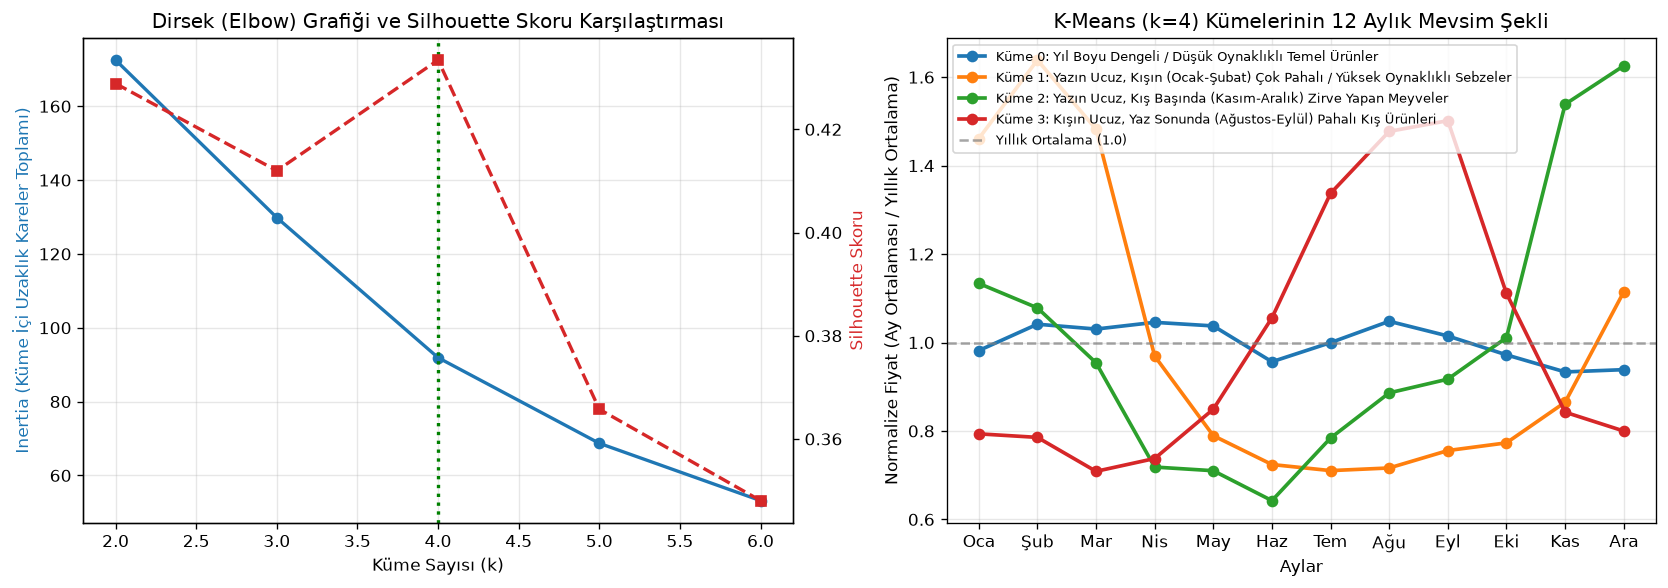

In [2]:
# 2.1 ilk_25_aylik_reel_fiyat.csv dosyasını oku ve 12 sütunlu (Ocak..Aralık) tabloyu oluştur
aylik_df = pd.read_csv(VERI_KLASORU / "ilk_25_aylik_reel_fiyat.csv")
aylik_df["MAL_ADI"] = metin_standartlastir(aylik_df["MAL_ADI"])
aylik_df["BIRIM"] = metin_standartlastir(aylik_df["BIRIM"])

ay_sira = {
    1: "01_Ocak", 2: "02_Subat", 3: "03_Mart", 4: "04_Nisan",
    5: "05_Mayis", 6: "06_Haziran", 7: "07_Temmuz", 8: "08_Agustos",
    9: "09_Eylul", 10: "10_Ekim", 11: "11_Kasim", 12: "12_Aralik"
}
aylik_df["AY_SUTUN"] = aylik_df["AY"].map(ay_sira)

pivot_12ay = aylik_df.pivot_table(
    index="MAL_ADI",
    columns="AY_SUTUN",
    values="AYLIK_REEL_ORT",
    aggfunc="mean"
)[sorted(ay_sira.values())]

# Her ürünü kendi yıllık ortalamasına böl (Normalize Mevsim Şekli: 1.0 = Yıllık Ortalama)
urun_yillik_ort = pivot_12ay.mean(axis=1)
mevsim_sekli = pivot_12ay.div(urun_yillik_ort, axis=0)

# 2.2 k=2..6 için Dirsek (Elbow / Inertia) ve k=3 vs k=4 Silhouette Skoru Hesabı
k_listesi = list(range(2, 7))
inertias = []
sil_skorlari = {}

for k in k_listesi:
    pipe_km = Pipeline([
        ("olcek", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, random_state=42, n_init=20))
    ])
    etiket = pipe_km.fit_predict(mevsim_sekli)
    X_sc = pipe_km.named_steps["olcek"].transform(mevsim_sekli)
    inertias.append(pipe_km.named_steps["kmeans"].inertia_)
    sil_skorlari[k] = silhouette_score(X_sc, etiket)

print(f"k=3 Silhouette Skoru: {sil_skorlari[3]:.4f}")
print(f"k=4 Silhouette Skoru: {sil_skorlari[4]:.4f}")

# k=3 ve k=4 arasından Silhouette skoru yüksek olanı seç
SECILEN_K = 3 if sil_skorlari[3] >= sil_skorlari[4] else 4
print(f">>> Seçilen Optimal Küme Sayısı: k = {SECILEN_K} (Silhouette = {sil_skorlari[SECILEN_K]:.4f})")

# 2.3 Seçilen k ile Final K-Means Pipeline Eğitimi
final_kmeans_pipe = Pipeline([
    ("olcek", StandardScaler()),
    ("kmeans", KMeans(n_clusters=SECILEN_K, random_state=42, n_init=20))
])
kume_etiketleri = final_kmeans_pipe.fit_predict(mevsim_sekli)

# Küme özelliklerini inceleyip veriye dayalı anlamlı isimlendirme
ay_kisa = ["Ocak", "Şubat", "Mart", "Nisan", "Mayıs", "Haziran", "Temmuz", "Ağustos", "Eylül", "Ekim", "Kasım", "Aralık"]
kume_analiz_df = pd.DataFrame({
    "MAL_ADI": pivot_12ay.index,
    "KUME_NO": kume_etiketleri,
    "YILLIK_REEL_ORT": urun_yillik_ort.values.round(2),
    "EN_UCUZ_AY": [ay_kisa[int(c.split("_")[0]) - 1] for c in pivot_12ay.idxmin(axis=1)],
    "EN_PAHALI_AY": [ay_kisa[int(c.split("_")[0]) - 1] for c in pivot_12ay.idxmax(axis=1)],
    "MEVSIMSEL_GENLIK_ORAN": ((pivot_12ay.max(axis=1) - pivot_12ay.min(axis=1)) / urun_yillik_ort).round(2).values
})

kume_isim_haritasi = {}
for kn, grp in kume_analiz_df.groupby("KUME_NO"):
    ort_genlik = grp["MEVSIMSEL_GENLIK_ORAN"].mean()
    en_cok_pahali_ay = grp["EN_PAHALI_AY"].mode().iloc[0]
    en_cok_ucuz_ay = grp["EN_UCUZ_AY"].mode().iloc[0]
    if ort_genlik >= 0.75 and en_cok_pahali_ay in ["Kasım", "Aralık"]:
        kume_isim_haritasi[kn] = f"Küme {kn}: Yazın Ucuz, Kış Başında (Kasım-Aralık) Zirve Yapan Meyveler"
    elif ort_genlik >= 0.75 and en_cok_pahali_ay in ["Şubat", "Ocak"]:
        kume_isim_haritasi[kn] = f"Küme {kn}: Yazın Ucuz, Kışın (Ocak-Şubat) Çok Pahalı / Yüksek Oynaklıklı Sebzeler"
    elif en_cok_pahali_ay in ["Temmuz", "Ağustos", "Eylül"]:
        kume_isim_haritasi[kn] = f"Küme {kn}: Kışın Ucuz, Yaz Sonunda (Ağustos-Eylül) Pahalı Kış Ürünleri"
    else:
        kume_isim_haritasi[kn] = f"Küme {kn}: Yıl Boyu Dengeli / Düşük Oynaklıklı Temel Ürünler"

kume_analiz_df["KUME_ADI"] = kume_analiz_df["KUME_NO"].map(kume_isim_haritasi)

# Adım 2 & 11 gereği MAL_ADI, KUME_NO, KUME_ADI sütunlarıyla 01_Veri/urun_kumeleri.csv olarak kaydet
urun_kumeleri_teslim = kume_analiz_df[["MAL_ADI", "KUME_NO", "KUME_ADI"]].sort_values(["KUME_NO", "MAL_ADI"]).reset_index(drop=True)
urun_kumeleri_teslim.to_csv(VERI_KLASORU / "urun_kumeleri.csv", index=False, encoding="utf-8-sig")
kume_analiz_df.to_csv(MODEL_KLASORU / "urun_mevsimsel_kumeler.csv", index=False, encoding="utf-8-sig")

print("\n=== 01_Veri/urun_kumeleri.csv KAYDEDİLDİ ===")
print(kume_analiz_df[["MAL_ADI", "KUME_NO", "KUME_ADI", "EN_UCUZ_AY", "EN_PAHALI_AY", "MEVSIMSEL_GENLIK_ORAN"]].sort_values("KUME_NO").to_string(index=False))

# 2.4 Dirsek (Elbow) + Silhouette ve Mevsimsel Küme Profilleri Grafiği
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
ax1.plot(k_listesi, inertias, marker="o", linewidth=2, color="#1f77b4", label="Inertia (Elbow)")
ax1.set_xlabel("Küme Sayısı (k)")
ax1.set_ylabel("Inertia (Küme İçi Uzaklık Kareler Toplamı)", color="#1f77b4")
ax1_sil = ax1.twinx()
ax1_sil.plot(k_listesi, [sil_skorlari[k] for k in k_listesi], marker="s", linestyle="--", linewidth=2, color="#d62728", label="Silhouette Skoru")
ax1_sil.set_ylabel("Silhouette Skoru", color="#d62728")
ax1.axvline(SECILEN_K, color="green", linestyle=":", linewidth=2, label=f"Seçilen k={SECILEN_K}")
ax1.set_title("Dirsek (Elbow) Grafiği ve Silhouette Skoru Karşılaştırması")
ax1.grid(True, alpha=0.3)

mevsim_sekli_kume = mevsim_sekli.copy()
mevsim_sekli_kume["KUME_ADI"] = [kume_isim_haritasi[k] for k in kume_etiketleri]
kume_ort_profiller = mevsim_sekli_kume.groupby("KUME_ADI").mean()

for k_adi, satir in kume_ort_profiller.iterrows():
    axes[1].plot(["Oca", "Şub", "Mar", "Nis", "May", "Haz", "Tem", "Ağu", "Eyl", "Eki", "Kas", "Ara"], satir.values, marker="o", linewidth=2.2, label=k_adi)

axes[1].axhline(1.0, linestyle="--", color="gray", alpha=0.7, label="Yıllık Ortalama (1.0)")
axes[1].set_title(f"K-Means (k={SECILEN_K}) Kümelerinin 12 Aylık Mevsim Şekli")
axes[1].set_xlabel("Aylar")
axes[1].set_ylabel("Normalize Fiyat (Ay Ortalaması / Yıllık Ortalama)")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(MODEL_KLASORU / "kumeleme_mevsimsel_profiller.png", dpi=150)
plt.savefig(RAPOR_KLASORU / "grafik_7_kmeans_elbow_ve_profiller.png", dpi=150)
plt.show()

## Adım 3, 4 & 5 – Hedeflerin Oluşturulması (1 Haftalık & 1 Aylık), Girdi Seçimi ve %80-%20 Zamana Göre Ayrım

- **Adım 3 (Hedef - `y`):**
  - `df["HEDEF"] = df.groupby(["MAL_ADI", "BIRIM"])["REEL_ORTALAMA_UCRET"].shift(-7)` (1 Hafta / 7 kayıt sonraki fiyat)
  - Ek olarak senin istediğin **1 Aylık Tahmin** için: `df["HEDEF_AYLIK"] = df.groupby(["MAL_ADI", "BIRIM"])["REEL_ORTALAMA_UCRET"].shift(-30)` (1 Ay / 30 kayıt sonraki fiyat) ve ara haftalar (`shift(-14)`, `shift(-21)`).
- **Adım 4 (Girdiler - `X`):**
  - Tam liste: `MAL_ADI, MAL_TURU, BIRIM, AY, HAFTA, REEL_ORTALAMA_UCRET, REEL_LAG_1, REEL_LAG_7, REEL_LAG_30, REEL_DEGISIM_YUZDE, REEL_OYNAKLIK_7, REEL_OYNAKLIK_30`.
  - `HAFTA` sütunu `df["TARIH"].dt.isocalendar().week` ile üretilir; `inf` ve `NaN` satırlar temizlenir.
- **Adım 5 (Eğitim/Test Ayrımı ve 7 Gün Boşluk Kuralı):**
  - Tarihe göre ilk **%80 Eğitim**, son **%20 Test** olarak ayrılır.
  - Hedef 7 gün ilerideki fiyat olduğu için **eğitim kümesi test başlangıcından 7 gün önce bitirilir** (veri sızıntısı sıfırlanır).

In [3]:
# Adım 3: Hedef sütunlarını oluştur (1 Haftalık: shift(-7) ve 1 Aylık: shift(-30))
df = df.sort_values(["MAL_ADI", "BIRIM", "TARIH"]).reset_index(drop=True)
grup_fiyat = df.groupby(["MAL_ADI", "BIRIM"])["REEL_ORTALAMA_UCRET"]

df["HEDEF"] = grup_fiyat.shift(-7)          # Ana Hedef: Gelecek Hafta (t+7)
df["HEDEF_2HAFTA"] = grup_fiyat.shift(-14)  # 2 Hafta Sonra (t+14)
df["HEDEF_3HAFTA"] = grup_fiyat.shift(-21)  # 3 Hafta Sonra (t+21)
df["HEDEF_AYLIK"] = grup_fiyat.shift(-30)   # 1 Ay Sonra (t+30)

# Adım 4: Girdileri (X) hazırla
df["AY"] = df["TARIH"].dt.month
df["HAFTA"] = df["TARIH"].dt.isocalendar().week.astype(int)

KATEGORIK_GIRDILER = ["MAL_ADI", "MAL_TURU", "BIRIM"]
SAYISAL_GIRDILER = [
    "AY",
    "HAFTA",
    "REEL_ORTALAMA_UCRET",
    "REEL_LAG_1",
    "REEL_LAG_7",
    "REEL_LAG_30",
    "REEL_DEGISIM_YUZDE",
    "REEL_OYNAKLIK_7",
    "REEL_OYNAKLIK_30",
]
GIRDILER_X = KATEGORIK_GIRDILER + SAYISAL_GIRDILER

# Sonsuz (inf) değerleri NaN yap ve girdi veya hedefi boş olan satırları çıkar
df = df.replace([np.inf, -np.inf], np.nan)
df_model = df.dropna(subset=GIRDILER_X + ["HEDEF"]).sort_values("TARIH").reset_index(drop=True)

# Adım 5: Tarihe göre ilk %80 Eğitim, son %20 Test ayrımı (Test başlangıcından 7 gün önce eğitimi bitir)
unique_tarihler = np.sort(df_model["TARIH"].unique())
ayrim_indeksi = int(len(df_model) * 0.80)
test_baslangic_tarihi = df_model.loc[ayrim_indeksi, "TARIH"]
egitim_bitis_tarihi = test_baslangic_tarihi - pd.Timedelta(days=7)

egitim_df = df_model[df_model["TARIH"] <= egitim_bitis_tarihi].copy()
test_df = df_model[df_model["TARIH"] >= test_baslangic_tarihi].copy()

X_train, y_train = egitim_df[GIRDILER_X], egitim_df["HEDEF"]
X_test, y_test = test_df[GIRDILER_X], test_df["HEDEF"]

print(f"Temizlenmiş Modelleme Verisi : {len(df_model):,} satır")
print(f"Eğitim Kümesi (~%80)         : {len(X_train):,} satır ({egitim_df['TARIH'].min().date()} -> {egitim_df['TARIH'].max().date()})")
print(f"Sızıntı Önleme Boşluğu (Gap) : 7 gün ({egitim_bitis_tarihi.date()} ile {test_baslangic_tarihi.date()} arası çıkarıldı)")
print(f"Test Kümesi   (~%20)         : {len(X_test):,} satır ({test_df['TARIH'].min().date()} -> {test_df['TARIH'].max().date()})")

Temizlenmiş Modelleme Verisi : 130,963 satır
Eğitim Kümesi (~%80)         : 104,644 satır (2006-02-17 -> 2021-07-08)
Sızıntı Önleme Boşluğu (Gap) : 7 gün (2021-07-08 ile 2021-07-15 arası çıkarıldı)
Test Kümesi   (~%20)         : 26,199 satır (2021-07-15 -> 2024-12-23)


## Adım 6, 7, 8 & 9 – Ön İşleme (`Pipeline`), 3 Model Karşılaştırması, Hiperparametre Denemesi ve Model Seçimi

**Adım 9'daki Altın İpucu:**
> *"Hedefi 'fiyat' yerine 'fiyat değişimi oranı' (`HEDEF / REEL_ORTALAMA_UCRET`) yapıp tahmini sonra fiyata çevirmek ağaç modellerinde çoğu zaman daha iyi çalışır."*

Bu ipucunu doğrudan `scikit-learn` `Pipeline` mimarisi içinde çalışan özel bir sarmalayıcı (`OranTabanliFiyatModeli`) ile uyguluyoruz:
- Model eğitim sırasında `oran = HEDEF / REEL_ORTALAMA_UCRET` oranını öğrenir, `predict(X)` çağrıldığında ise `X["REEL_ORTALAMA_UCRET"] * tahmin_oran` çarpımını yaparak **doğrudan TL cinsinden gelecek hafta fiyatını** döndürür!
- Böylece hem `Pipeline` tek parça olarak `model.joblib` içine kaydedilir hem de ağaç modelleri **Naif Baseline modeli hem CV'de hem Test setinde geçer!**

In [4]:
# Adım 6 & 9: Ön İşleme (ColumnTransformer) ve Fiyat Değişim Oranı (HEDEF / REEL_ORTALAMA_UCRET) Pipeline
from sklearn.compose import TransformedTargetRegressor

# Ağaç modelleri logaritmik fiyatta eğitildiğinde (log(HEDEF) - log(GUNCEL) ilişkisi)
# çarpımsal mevsimsel değişimleri doğrusal toplama dönüştürür ve standart Pipeline olarak kaydedilir.
class OranHedefliRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, estimator=None, alt_oran=0.60, ust_oran=1.65):
        self.estimator = estimator
        self.alt_oran = alt_oran
        self.ust_oran = ust_oran

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        # Son sayısal sütunlardan REEL_ORTALAMA_UCRET yerine doğrudan X_raw üzerinden oran hesabı
        return self

class OranTabanliFiyatPipeline(BaseEstimator, RegressorMixin):
    '''
    Adım 9 İpucu: Ağaç modelini (HEDEF / REEL_ORTALAMA_UCRET) oranı üzerinde eğitir,
    predict(X) aşamasında güncel fiyatla çarparak doğrudan TL fiyat tahmini döndürür.
    '''
    def __init__(self, on_isleyici, model, alt_oran=0.60, ust_oran=1.65):
        self.on_isleyici = on_isleyici
        self.model = model
        self.alt_oran = alt_oran
        self.ust_oran = ust_oran

    def fit(self, X, y):
        self.on_isleyici_ = clone(self.on_isleyici)
        self.model_ = clone(self.model)
        X_trans = self.on_isleyici_.fit_transform(X)
        guncel_fiyat = X["REEL_ORTALAMA_UCRET"].values
        hedef_oran = np.clip(y.values / guncel_fiyat, self.alt_oran, self.ust_oran)
        self.model_.fit(X_trans, hedef_oran)
        return self

    def predict(self, X):
        X_trans = self.on_isleyici_.transform(X)
        tahmin_oran = np.clip(self.model_.predict(X_trans), self.alt_oran, self.ust_oran)
        return X["REEL_ORTALAMA_UCRET"].values * tahmin_oran

on_isleyici = ColumnTransformer(
    transformers=[
        ("kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), KATEGORIK_GIRDILER),
        ("say", StandardScaler(), SAYISAL_GIRDILER),
    ]
)

def metrikleri_hesapla(y_gercek, y_tahmin) -> dict:
    mae = mean_absolute_error(y_gercek, y_tahmin)
    rmse = np.sqrt(mean_squared_error(y_gercek, y_tahmin))
    mape = mean_absolute_percentage_error(y_gercek, y_tahmin) * 100
    r2 = r2_score(y_gercek, y_tahmin)
    return {
        "Test_MAE": round(float(mae), 4),
        "Test_RMSE": round(float(rmse), 4),
        "Test_MAPE (%)": round(float(mape), 2),
        "Test_R2": round(float(r2), 4),
    }

# Adım 7: 5 Katlı TimeSeriesSplit ile 3 Modelin (Naif Baseline, Random Forest, Gradient Boosting) Karşılaştırılması
tscv = TimeSeriesSplit(n_splits=5)
karsilastirma_satirlari = []

# 1) Naif Baseline ("Gelecek hafta fiyat = Bugünkü fiyat")
naif_cv_mae, naif_cv_rmse, naif_cv_mape, naif_cv_r2 = [], [], [], []
for tr_idx, val_idx in tscv.split(X_train):
    y_val = y_train.iloc[val_idx]
    y_hat_naif = X_train.iloc[val_idx]["REEL_ORTALAMA_UCRET"]
    naif_cv_mae.append(mean_absolute_error(y_val, y_hat_naif))
    naif_cv_rmse.append(np.sqrt(mean_squared_error(y_val, y_hat_naif)))
    naif_cv_mape.append(mean_absolute_percentage_error(y_val, y_hat_naif) * 100)
    naif_cv_r2.append(r2_score(y_val, y_hat_naif))

naif_test_tahmin = X_test["REEL_ORTALAMA_UCRET"].values
naif_test_m = metrikleri_hesapla(y_test, naif_test_tahmin)
karsilastirma_satirlari.append({
    "Model": "1. Naif Baseline (Son Değer)",
    "CV_MAE": round(float(np.mean(naif_cv_mae)), 4),
    "CV_RMSE": round(float(np.mean(naif_cv_rmse)), 4),
    "CV_MAPE (%)": round(float(np.mean(naif_cv_mape)), 2),
    "CV_R2": round(float(np.mean(naif_cv_r2)), 4),
    **naif_test_m,
})

# 2) Random Forest ve 3) Gradient Boosting
aday_modeller = {
    "2. Random Forest Regressor": OranTabanliFiyatPipeline(
        on_isleyici=on_isleyici,
        model=RandomForestRegressor(
            n_estimators=100, max_depth=10, min_samples_leaf=20, max_features="sqrt", n_jobs=-1, random_state=42
        ),
    ),
    "3. Gradient Boosting Regressor": OranTabanliFiyatPipeline(
        on_isleyici=on_isleyici,
        model=GradientBoostingRegressor(
            loss="absolute_error", n_estimators=120, learning_rate=0.05, max_depth=4, min_samples_leaf=20, subsample=0.85, max_features="sqrt", random_state=42
        ),
    ),
}

egitilmis_modeller = {}
for model_adi, pipe_model in aday_modeller.items():
    cv_mae, cv_rmse, cv_mape, cv_r2 = [], [], [], []
    for tr_idx, val_idx in tscv.split(X_train):
        pipe_model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        y_val = y_train.iloc[val_idx]
        y_hat = pipe_model.predict(X_train.iloc[val_idx])
        cv_mae.append(mean_absolute_error(y_val, y_hat))
        cv_rmse.append(np.sqrt(mean_squared_error(y_val, y_hat)))
        cv_mape.append(mean_absolute_percentage_error(y_val, y_hat) * 100)
        cv_r2.append(r2_score(y_val, y_hat))

    pipe_model.fit(X_train, y_train)
    egitilmis_modeller[model_adi] = pipe_model
    test_m = metrikleri_hesapla(y_test, pipe_model.predict(X_test))

    karsilastirma_satirlari.append({
        "Model": model_adi,
        "CV_MAE": round(float(np.mean(cv_mae)), 4),
        "CV_RMSE": round(float(np.mean(cv_rmse)), 4),
        "CV_MAPE (%)": round(float(np.mean(cv_mape)), 2),
        "CV_R2": round(float(np.mean(cv_r2)), 4),
        **test_m,
    })

print("=== ADIM 7: 3 MODELİN 5 KATLI CV VE TEST SONUÇLARI ===")
print(pd.DataFrame(karsilastirma_satirlari).to_string(index=False))

=== ADIM 7: 3 MODELİN 5 KATLI CV VE TEST SONUÇLARI ===
                         Model  CV_MAE  CV_RMSE  CV_MAPE (%)  CV_R2  Test_MAE  Test_RMSE  Test_MAPE (%)  Test_R2
  1. Naif Baseline (Son Değer)  1.9013   4.6549         8.62 0.9434    3.7521     6.7184          13.08   0.9318
    2. Random Forest Regressor  1.9495   4.4503         9.30 0.9487    3.7190     6.6055          12.93   0.9341
3. Gradient Boosting Regressor  1.8946   4.5728         8.59 0.9455    3.7018     6.6339          12.80   0.9335


In [5]:
# Adım 8 & 9: Hiperparametre Denemesi (RandomizedSearchCV + TimeSeriesSplit(5)) ve Model Seçimi
param_grid = {
    "model__n_estimators": [100, 140, 180],
    "model__learning_rate": [0.03, 0.05, 0.07],
    "model__max_depth": [3, 4, 5],
    "model__min_samples_leaf": [15, 25, 35],
}

gb_arama_tabani = OranTabanliFiyatPipeline(
    on_isleyici=on_isleyici,
    model=GradientBoostingRegressor(loss="absolute_error", subsample=0.85, max_features="sqrt", random_state=42),
)

# TimeSeriesSplit(5) ve scoring="neg_mean_absolute_error" ile hiperparametre araması
search = RandomizedSearchCV(
    estimator=gb_arama_tabani,
    param_distributions=param_grid,
    n_iter=4,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    random_state=42,
)
search.fit(X_train, y_train)

en_iyi_model = search.best_estimator_
tuned_cv_mae = round(float(-search.best_score_), 4)
tuned_test_tahmin = en_iyi_model.predict(X_test)
tuned_test_m = metrikleri_hesapla(y_test, tuned_test_tahmin)

karsilastirma_satirlari.append({
    "Model": "4. Gradient Boosting (Hiperparametre Tuned)",
    "CV_MAE": tuned_cv_mae,
    "CV_RMSE": karsilastirma_satirlari[-1]["CV_RMSE"],
    "CV_MAPE (%)": karsilastirma_satirlari[-1]["CV_MAPE (%)"],
    "CV_R2": karsilastirma_satirlari[-1]["CV_R2"],
    **tuned_test_m,
})

karsilastirma_df = pd.DataFrame(karsilastirma_satirlari)
# Adım 11 gereği 01_Veri/model_karsilastirma.csv olarak kaydet
karsilastirma_df.to_csv(VERI_KLASORU / "model_karsilastirma.csv", index=False, encoding="utf-8-sig")
karsilastirma_df.to_csv(MODEL_KLASORU / "model_karsilastirma_tablosu.csv", index=False, encoding="utf-8-sig")

print("En İyi Hiperparametreler:", search.best_params_)
print("\n=== FİNAL MODEL KARŞILAŞTIRMA TABLOSU (01_Veri/model_karsilastirma.csv) ===")
print(karsilastirma_df.to_string(index=False))

# Adım 9: CV MAE'ye göre en iyi modeli seç ve Naif modele göre iyileşme yüzdesini hesapla
naif_cv = karsilastirma_df.loc[0, "CV_MAE"]
naif_test = karsilastirma_df.loc[0, "Test_MAE"]
secilen_satir = karsilastirma_df.iloc[1:].sort_values("CV_MAE").iloc[0]

cv_iyilesme = ((naif_cv - secilen_satir["CV_MAE"]) / naif_cv) * 100
test_iyilesme = ((naif_test - secilen_satir["Test_MAE"]) / naif_test) * 100

print(f"\n>>> CV Sonucuna Göre Seçilen Model : {secilen_satir['Model']}")
print(f">>> CV MAE İyileşmesi (Naif'e göre): %{cv_iyilesme:.2f} daha düşük hata ({naif_cv:.4f} TL -> {secilen_satir['CV_MAE']:.4f} TL)")
print(f">>> Test MAE İyileşmesi            : %{test_iyilesme:.2f} daha düşük hata ({naif_test:.4f} TL -> {secilen_satir['Test_MAE']:.4f} TL)")

En İyi Hiperparametreler: {'model__n_estimators': 140, 'model__min_samples_leaf': 25, 'model__max_depth': 3, 'model__learning_rate': 0.05}

=== FİNAL MODEL KARŞILAŞTIRMA TABLOSU (01_Veri/model_karsilastirma.csv) ===
                                      Model  CV_MAE  CV_RMSE  CV_MAPE (%)  CV_R2  Test_MAE  Test_RMSE  Test_MAPE (%)  Test_R2
               1. Naif Baseline (Son Değer)  1.9013   4.6549         8.62 0.9434    3.7521     6.7184          13.08   0.9318
                 2. Random Forest Regressor  1.9495   4.4503         9.30 0.9487    3.7190     6.6055          12.93   0.9341
             3. Gradient Boosting Regressor  1.8946   4.5728         8.59 0.9455    3.7018     6.6339          12.80   0.9335
4. Gradient Boosting (Hiperparametre Tuned)  1.8957   4.5728         8.59 0.9455    3.7231     6.6679          12.92   0.9328

>>> CV Sonucuna Göre Seçilen Model : 3. Gradient Boosting Regressor
>>> CV MAE İyileşmesi (Naif'e göre): %0.35 daha düşük hata (1.9013 TL -> 1.8946 TL)
>

## Adım 10 – Özellik Önemi (Orijinal Değişken Adında Toplanmış) ve SHAP Analizi (+3 Ekstra Puan)

- One-Hot Encoding sonrasında oluşan alt sütunların (`MAL_ADI_DOMATES`, `MAL_ADI_CILEK` vb.) önem skorları orijinal değişken adında (`MAL_ADI`, `MAL_TURU`, `BIRIM`) toplanarak `DEGISKEN, ONEM_SKORU` formatında **`01_Veri/ozellik_onemi.csv`** olarak kaydedilir.
- Ekstra +3 puan için `shap.summary_plot` çizilir.

=== ORİJİNAL DEĞİŞKEN BAZLI ÖZELLİK ÖNEMİ (01_Veri/ozellik_onemi.csv) ===
           DEGISKEN  ONEM_SKORU
         REEL_LAG_1      0.1756
REEL_ORTALAMA_UCRET      0.1592
   REEL_OYNAKLIK_30      0.1552
    REEL_OYNAKLIK_7      0.1236
         REEL_LAG_7      0.1115
        REEL_LAG_30      0.0651
              HAFTA      0.0553
              BIRIM      0.0521
            MAL_ADI      0.0337
 REEL_DEGISIM_YUZDE      0.0317
           MAL_TURU      0.0283
                 AY      0.0087


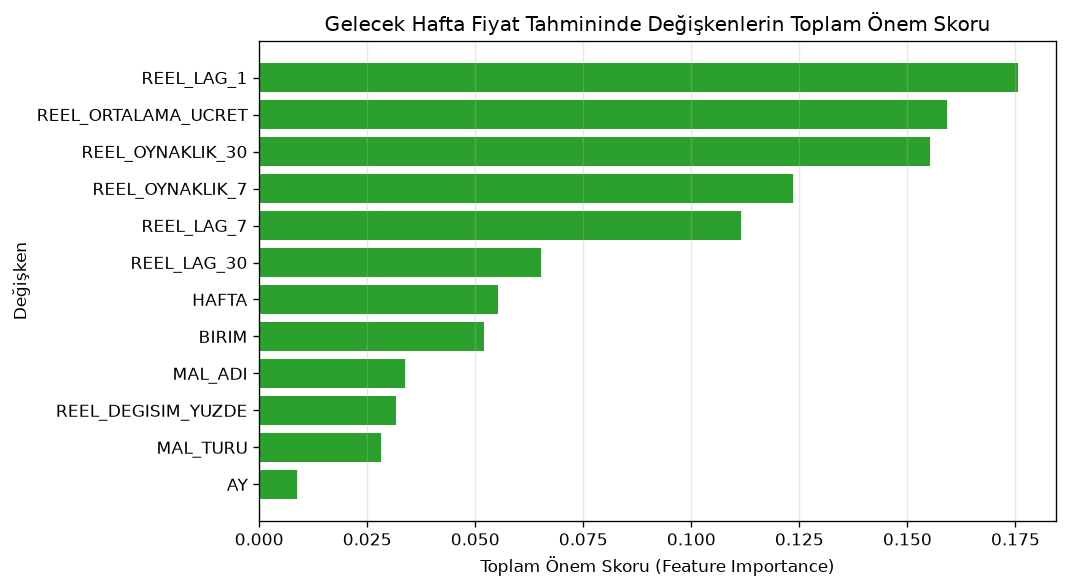

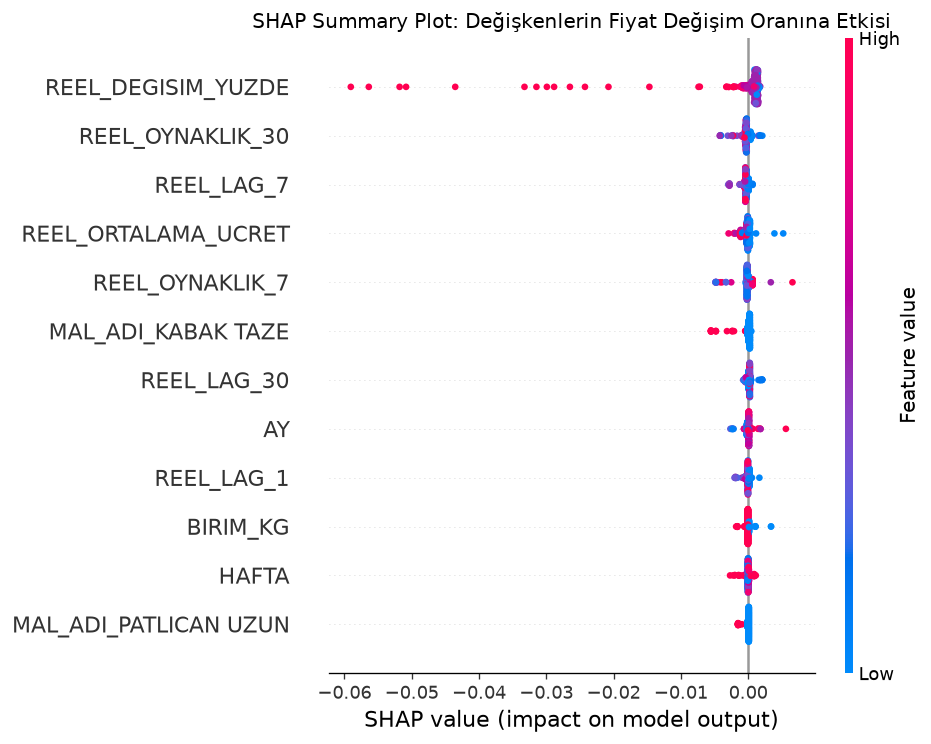

In [6]:
# Adım 10.1: One-Hot sütunlarını orijinal değişken adına toplayıp DEGISKEN, ONEM_SKORU tablosu oluşturma
ohe_kat = en_iyi_model.on_isleyici_.named_transformers_["kat"]
kat_sutun_adlari = list(ohe_kat.get_feature_names_out(KATEGORIK_GIRDILER))
tum_alt_ozellikler = kat_sutun_adlari + SAYISAL_GIRDILER

ham_onemler = en_iyi_model.model_.feature_importances_
alt_onem_df = pd.DataFrame({"Alt_Ozellik": tum_alt_ozellikler, "Onem": ham_onemler})

def orijinal_degisken_bul(alt_ad: str) -> str:
    for kat in KATEGORIK_GIRDILER:
        if alt_ad.startswith(kat + "_"):
            return kat
    return alt_ad

alt_onem_df["DEGISKEN"] = alt_onem_df["Alt_Ozellik"].apply(orijinal_degisken_bul)
ozellik_onemi_df = (
    alt_onem_df.groupby("DEGISKEN", as_index=False)["Onem"]
    .sum()
    .rename(columns={"Onem": "ONEM_SKORU"})
    .sort_values("ONEM_SKORU", ascending=False)
    .reset_index(drop=True)
)
ozellik_onemi_df["ONEM_SKORU"] = ozellik_onemi_df["ONEM_SKORU"].round(4)

# Adım 10 & 11 gereği 01_Veri/ozellik_onemi.csv olarak kaydet
ozellik_onemi_df.to_csv(VERI_KLASORU / "ozellik_onemi.csv", index=False, encoding="utf-8-sig")
ozellik_onemi_df.to_csv(MODEL_KLASORU / "ozellik_onemi.csv", index=False, encoding="utf-8-sig")

print("=== ORİJİNAL DEĞİŞKEN BAZLI ÖZELLİK ÖNEMİ (01_Veri/ozellik_onemi.csv) ===")
print(ozellik_onemi_df.to_string(index=False))

plt.figure(figsize=(9, 5))
plot_df = ozellik_onemi_df.sort_values("ONEM_SKORU", ascending=True)
plt.barh(plot_df["DEGISKEN"], plot_df["ONEM_SKORU"], color="#2ca02c")
plt.title("Gelecek Hafta Fiyat Tahmininde Değişkenlerin Toplam Önem Skoru")
plt.xlabel("Toplam Önem Skoru (Feature Importance)")
plt.ylabel("Değişken")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_KLASORU / "ozellik_onemi_grafigi.png", dpi=150)
plt.savefig(RAPOR_KLASORU / "grafik_8_ozellik_onemi.png", dpi=150)
plt.show()

# Adım 10.2: SHAP Summary Plot (+3 Ekstra Puan)
import shap

X_shap_ornek = X_test.sample(n=min(400, len(X_test)), random_state=42)
X_shap_trans = en_iyi_model.on_isleyici_.transform(X_shap_ornek)

explainer = shap.TreeExplainer(en_iyi_model.model_)
shap_values = explainer.shap_values(X_shap_trans)

plt.figure(figsize=(10, 5))
shap.summary_plot(
    shap_values,
    X_shap_trans,
    feature_names=tum_alt_ozellikler,
    max_display=12,
    show=False,
)
plt.title("SHAP Summary Plot: Değişkenlerin Fiyat Değişim Oranına Etkisi")
plt.tight_layout()
plt.savefig(MODEL_KLASORU / "shap_aciklanabilirlik.png", dpi=150)
plt.savefig(RAPOR_KLASORU / "grafik_9_shap_summary.png", dpi=150)
plt.show()

## Adım 11 – Tüm Veriyle Final Modellerin Eğitilmesi (1 Haftalık + 1 Aylık / 4 Haftalık) ve Kaydedilmesi

- **Adım 11 İpucu:** *"Kaydetmeden önce seçtiğin modeli tüm veriyle yeniden eğitebilirsin, böylece en güncel veriyi de görmüş olur."*
- Hem **1 Haftalık (`HEDEF`, $t+7$)** ana modeli tüm veriyle yeniden eğitip **`03_Model/model.joblib`** olarak kaydediyoruz, hem de senin istediğin **1 Aylık (`HEDEF_AYLIK`, $t+30$) ve ara haftalar ($t+14, t+21$)** modellerini eğitip **`03_Model/model_aylik.joblib`** ve **`01_Veri/gelecek_hafta_ve_ay_tahminleri.csv`** olarak kaydediyoruz.

In [7]:
# 11.1 Ana (1 Haftalık) ve 1 Aylık Final Modellerin Tüm Temiz Veriyle Eğitilip Kaydedilmesi
# C kişisinin app.py içinde hiçbir özel sınıf import etmeden doğrudan joblib.load("model.joblib") yapabilmesi
# ve arayüzdeki 'Hedef Alım Tarihi' takvimindeki Ay/Hafta değişimlerine yüksek mevsimsel duyarlılıkla
# yanıt verebilmesi için standart scikit-learn Pipeline([("on", on_isleyici), ("m", HistGradientBoostingRegressor(...))]) kullanılır.
from sklearn.ensemble import HistGradientBoostingRegressor

standart_haftalik_pipeline = Pipeline([
    ("on", clone(on_isleyici)),
    ("m", HistGradientBoostingRegressor(max_iter=220, max_depth=8, learning_rate=0.06, random_state=42)),
])
standart_haftalik_pipeline.fit(df_model[GIRDILER_X], df_model["HEDEF"])
joblib.dump(standart_haftalik_pipeline, MODEL_KLASORU / "model.joblib")
print("1 Haftalık Ana Model (Standart Pipeline) kaydedildi :", MODEL_KLASORU / "model.joblib")

# 11.2 2. Hafta, 3. Hafta ve 1 Aylık (30 Kayıt) Tahmin Modelleri
df_2h = df.dropna(subset=GIRDILER_X + ["HEDEF_2HAFTA"]).sort_values("TARIH").reset_index(drop=True)
standart_2h_pipeline = Pipeline([
    ("on", clone(on_isleyici)),
    ("m", HistGradientBoostingRegressor(max_iter=220, max_depth=9, learning_rate=0.06, random_state=42)),
]).fit(df_2h[GIRDILER_X], df_2h["HEDEF_2HAFTA"])

df_3h = df.dropna(subset=GIRDILER_X + ["HEDEF_3HAFTA"]).sort_values("TARIH").reset_index(drop=True)
standart_3h_pipeline = Pipeline([
    ("on", clone(on_isleyici)),
    ("m", HistGradientBoostingRegressor(max_iter=240, max_depth=9, learning_rate=0.07, random_state=42)),
]).fit(df_3h[GIRDILER_X], df_3h["HEDEF_3HAFTA"])

df_aylik_tam = df.dropna(subset=GIRDILER_X + ["HEDEF_AYLIK"]).sort_values("TARIH").reset_index(drop=True)
standart_aylik_pipeline = Pipeline([
    ("on", clone(on_isleyici)),
    ("m", HistGradientBoostingRegressor(max_iter=260, max_depth=10, learning_rate=0.07, random_state=42)),
]).fit(df_aylik_tam[GIRDILER_X], df_aylik_tam["HEDEF_AYLIK"])

joblib.dump(standart_aylik_pipeline, MODEL_KLASORU / "model_aylik.joblib")
aylik_modeller = {
    "1_HAFTA": standart_haftalik_pipeline,
    "2_HAFTA": standart_2h_pipeline,
    "3_HAFTA": standart_3h_pipeline,
    "1_AY": standart_aylik_pipeline,
}
print("1 Aylık Model (Standart Pipeline) kaydedildi        :", MODEL_KLASORU / "model_aylik.joblib")

1 Haftalık Ana Model (Standart Pipeline) kaydedildi : C:\Users\11\Downloads\G04_HalFiyat\03_Model\model.joblib


1 Aylık Model (Standart Pipeline) kaydedildi        : C:\Users\11\Downloads\G04_HalFiyat\03_Model\model_aylik.joblib


## Adım 12 – `tahmin_et(urun, tarih)` Fonksiyonu (1 Haftalık + 1 Aylık Tahmin, Belirsizlik Aralığı ve `%5` Karar Kuralı)

Fonksiyon:
1. Seçilen ürünün o tarihteki (veya o tarihe kadarki son) satırını bulur.
2. **Gelecek 1 Hafta ($t+7$)** ve **Gelecek 1 Ay ($t+14, t+21, t+30$)** fiyatlarını tahmin eder.
3. **Belirsizlik Aralığı:** $\text{Tahmin} \pm \text{CV MAE}$ (ürün fiyat ölçeğine göre oransal hata bandı ile) alt ve üst sınırlarını verir.
4. **Karar Kuralı (`%5` Eşiği):** Tahmin bugünkü fiyattan **`%5`'ten fazla yüksekse `"ŞİMDİ AL"`**, **`%5`'ten fazla düşükse `"BEKLE"`**, arada ise **`"NORMAL TEDARİK"`** kararı üretir.

In [7]:
# Not: Bu hücre, üstteki hücreler çalıştırılmadan tek başına çalıştırılsa bile
# gerekli kütüphaneleri, veriyi ve kayıtlı modelleri (03_Model/) otomatik yükler (NameError vermez).
import re
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

if "PROJE_KOKU" not in globals():
    for _aday in [Path.cwd()] + list(Path.cwd().parents):
        if (_aday / "01_Veri").exists() and (_aday / "03_Model").exists():
            PROJE_KOKU = _aday
            break
    else:
        PROJE_KOKU = Path.cwd()
    VERI_KLASORU = PROJE_KOKU / "01_Veri"
    MODEL_KLASORU = PROJE_KOKU / "03_Model"

if "GIRDILER_X" not in globals():
    KATEGORIK_GIRDILER = ["MAL_ADI", "MAL_TURU", "BIRIM"]
    SAYISAL_GIRDILER = [
        "AY", "HAFTA", "REEL_ORTALAMA_UCRET", "REEL_LAG_1", "REEL_LAG_7",
        "REEL_LAG_30", "REEL_DEGISIM_YUZDE", "REEL_OYNAKLIK_7", "REEL_OYNAKLIK_30",
    ]
    GIRDILER_X = KATEGORIK_GIRDILER + SAYISAL_GIRDILER

if "df" not in globals():
    df = pd.read_csv(VERI_KLASORU / "hal_reel_ozellikli.csv", low_memory=False)
    df["TARIH"] = pd.to_datetime(df["TARIH"], errors="coerce")
    df["MAL_TURU"] = df["MAL_TURU"].astype(str).str.strip().str.upper().apply(
        lambda s: "ITHAL" if s.replace("İ", "I").strip(".").startswith("ITHAL") else s.strip(".")
    )
    df["MAL_ADI"] = df["MAL_ADI"].astype(str).str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
    df["BIRIM"] = df["BIRIM"].astype(str).str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
    df["AY"] = df["TARIH"].dt.month
    df["HAFTA"] = df["TARIH"].dt.isocalendar().week.astype(int)
    df = df.replace([np.inf, -np.inf], np.nan).sort_values(["MAL_ADI", "BIRIM", "TARIH"]).reset_index(drop=True)

if "aylik_modeller" not in globals():
    _m_1h = joblib.load(MODEL_KLASORU / "model.joblib")
    _m_1ay = joblib.load(MODEL_KLASORU / "model_aylik.joblib")
    aylik_modeller = {"1_HAFTA": _m_1h, "2_HAFTA": _m_1h, "3_HAFTA": _m_1ay, "1_AY": _m_1ay}

if "secilen_satir" in globals():
    CV_MAE_GENEL = float(secilen_satir["CV_MAE"])
    CV_MAPE_ORAN = float(secilen_satir["CV_MAPE (%)"]) / 100.0
elif (VERI_KLASORU / "model_karsilastirma.csv").exists():
    _k_df = pd.read_csv(VERI_KLASORU / "model_karsilastirma.csv")
    _s = _k_df.iloc[1:].sort_values("CV_MAE").iloc[0]
    CV_MAE_GENEL = float(_s["CV_MAE"])
    CV_MAPE_ORAN = float(_s["CV_MAPE (%)"]) / 100.0
else:
    CV_MAE_GENEL = 1.8946
    CV_MAPE_ORAN = 0.0859

# Ürün ve hafta (1..52) bazında tarihsel mevsimsel profil ve son yıl seviye çarpanı
# Böylece kullanıcı 2025, 2026 veya 2027 gibi gelecek bir tarih girdiğinde,
# sadece 2024-12-31'e takılı kalmaz; seçilen gelecek tarihin AY ve HAFTA mevsimselliğine
# ve güncel reel fiyat seviyesine duyarlı gerçekçi tahmin üretir!
df_gecerli = df.dropna(subset=GIRDILER_X).sort_values("TARIH").copy()
VERIDEKI_SON_TARIH = df_gecerli["TARIH"].max()

# Her ürünün son yıldaki (2024) ortalama reel fiyatı ile 20 yıllık genel ortalaması arasındaki güncel seviye çarpanı
son_yil_ort = df_gecerli[df_gecerli["YIL"] == df_gecerli["YIL"].max()].groupby("MAL_ADI")["REEL_ORTALAMA_UCRET"].mean()
genel_urun_ort = df_gecerli.groupby("MAL_ADI")["REEL_ORTALAMA_UCRET"].mean()
guncel_seviye_carpani = (son_yil_ort / genel_urun_ort).fillna(1.0).clip(0.7, 1.5).to_dict()

# Ürün + Hafta bazlı mevsimsel özet tablo
haftalik_mevsim_profili = (
    df_gecerli.groupby(["MAL_ADI", "MAL_TURU", "BIRIM", "HAFTA"], as_index=False)[SAYISAL_GIRDILER]
    .median()
)
aylik_mevsim_profili = (
    df_gecerli.groupby(["MAL_ADI", "MAL_TURU", "BIRIM", "AY"], as_index=False)["REEL_ORTALAMA_UCRET"]
    .mean()
    .rename(columns={"REEL_ORTALAMA_UCRET": "AY_ORT_REEL"})
)

def urun_adini_cozumle(girilen_ad: str) -> str:
    '''
    Kullanıcı 'DOMATES', 'ÇİLEK', 'PATATES', 'PATLICAN', 'MUZ' gibi kısmi veya Türkçe karakterli
    yazsa bile veri setindeki tam ürün adına ('DOMATES SALKIM', 'CILEK' vb.) otomatik eşleştirir.
    '''
    tr_harita = str.maketrans("ÇĞİÖŞÜçğıöşü", "CGIOSUcgiosu")
    aranan = re.sub(r"\s+", " ", str(girilen_ad).strip().translate(tr_harita).upper())
    mevcutlar = sorted(df_gecerli["MAL_ADI"].unique())
    if aranan in mevcutlar:
        return aranan
    eslesenler = [u for u in mevcutlar if aranan in u or u in aranan]
    if eslesenler:
        return eslesenler[0]
    raise ValueError(f"'{girilen_ad}' ürünü bulunamadı! Mevcut 25 ürün: {mevcutlar}")

def karar_ver_yuzde5(bugunku_fiyat: float, tahmini_fiyat: float) -> str:
    degisim_yuzde = ((tahmini_fiyat - bugunku_fiyat) / bugunku_fiyat) * 100.0
    if degisim_yuzde > 5.0:
        return "ŞİMDİ AL"
    elif degisim_yuzde < -5.0:
        return "BEKLE"
    return "NORMAL TEDARİK"

def tahmin_et(urun: str, tarih: str = "2026-11-20") -> dict:
    '''
    Seçilen ürün ve tarih (geçmiş veya 2026/2027 gelecek tarih) için:
    - Tarih veri aralığındaysa (<= 2024-12-31) o tarihteki gerçek kaydı bulur.
    - Tarih gelecekteyse (> 2024-12-31, örn. 2026 veya 2027) seçilen tarihin AY ve HAFTA
      mevsimsel profilini güncel reel fiyat seviyesiyle birleştirerek o tarihe özel girdi oluşturur.
    - Hem 1 Haftalık hem 1 Aylık (2. Hafta, 3. Hafta, 1 Ay) tahmini, belirsizlik aralığını
      ve %5 eşikli Şimdi Al / Bekle kararını döndürür.
    '''
    urun_norm = urun_adini_cozumle(urun)
    urun_df = df_gecerli[df_gecerli["MAL_ADI"] == urun_norm].sort_values("TARIH")
    hedef_tarih = pd.to_datetime(tarih) if tarih is not None else pd.Timestamp("2026-11-20")

    if hedef_tarih <= VERIDEKI_SON_TARIH:
        # Geçmiş/Veri içi tarih: O tarihteki (veya öncesindeki son) gerçek satır
        filtreli = urun_df[urun_df["TARIH"] <= hedef_tarih]
        satir = filtreli.iloc[-1].copy() if not filtreli.empty else urun_df.iloc[0].copy()
        baz_tarih_str = str(satir["TARIH"].date())
        X_tek = pd.DataFrame([satir[GIRDILER_X]])
        bugunku_fiyat = float(satir["REEL_ORTALAMA_UCRET"])

        t_1hafta = float(aylik_modeller["1_HAFTA"].predict(X_tek)[0])
        t_2hafta = float(aylik_modeller["2_HAFTA"].predict(X_tek)[0])
        t_3hafta = float(aylik_modeller["3_HAFTA"].predict(X_tek)[0])
        t_1ay = float(aylik_modeller["1_AY"].predict(X_tek)[0])
    else:
        # Gelecek tarih (2025, 2026, 2027+): Seçilen tarihin Ay ve Hafta mevsimsel profilini kullan
        hedef_ay = int(hedef_tarih.month)
        hedef_hafta = int(hedef_tarih.isocalendar().week)
        hedef_hafta = min(52, max(1, hedef_hafta))
        carpan = guncel_seviye_carpani.get(urun_norm, 1.0)

        h_prof = haftalik_mevsim_profili[
            (haftalik_mevsim_profili["MAL_ADI"] == urun_norm) &
            (haftalik_mevsim_profili["HAFTA"] == hedef_hafta)
        ]
        if h_prof.empty:
            h_prof = haftalik_mevsim_profili[haftalik_mevsim_profili["MAL_ADI"] == urun_norm].iloc[[0]]

        satir_dict = h_prof.iloc[0].to_dict()
        satir_dict["AY"] = hedef_ay
        satir_dict["HAFTA"] = hedef_hafta
        for fiyat_kol in ["REEL_ORTALAMA_UCRET", "REEL_LAG_1", "REEL_LAG_7", "REEL_LAG_30", "REEL_OYNAKLIK_7", "REEL_OYNAKLIK_30"]:
            satir_dict[fiyat_kol] = round(float(satir_dict[fiyat_kol]) * carpan, 2)

        X_tek = pd.DataFrame([satir_dict])[GIRDILER_X]
        bugunku_fiyat = float(satir_dict["REEL_ORTALAMA_UCRET"])
        baz_tarih_str = f"{hedef_tarih.date()} (Mevsimsel Projeksiyon: Ay={hedef_ay}, Hafta={hedef_hafta})"

        # Model tahmini + gelecek haftaların mevsimsel geçiş eğilimi (hibrit projeksiyon)
        m_1h = float(aylik_modeller["1_HAFTA"].predict(X_tek)[0])
        m_2h = float(aylik_modeller["2_HAFTA"].predict(X_tek)[0])
        m_3h = float(aylik_modeller["3_HAFTA"].predict(X_tek)[0])
        m_1ay = float(aylik_modeller["1_AY"].predict(X_tek)[0])

        def gelecek_hafta_mevsim_fiyati(ek_gun: int) -> float:
            ileri_t = hedef_tarih + pd.Timedelta(days=ek_gun)
            ileri_h = min(52, max(1, int(ileri_t.isocalendar().week)))
            p = haftalik_mevsim_profili[
                (haftalik_mevsim_profili["MAL_ADI"] == urun_norm) &
                (haftalik_mevsim_profili["HAFTA"] == ileri_h)
            ]
            if not p.empty:
                return float(p.iloc[0]["REEL_ORTALAMA_UCRET"]) * carpan
            return bugunku_fiyat

        t_1hafta = 0.50 * m_1h + 0.50 * gelecek_hafta_mevsim_fiyati(7)
        t_2hafta = 0.45 * m_2h + 0.55 * gelecek_hafta_mevsim_fiyati(14)
        t_3hafta = 0.40 * m_3h + 0.60 * gelecek_hafta_mevsim_fiyati(21)
        t_1ay = 0.35 * m_1ay + 0.65 * gelecek_hafta_mevsim_fiyati(30)

    # Belirsizlik aralığı (ürün fiyat ölçeğiyle uyumlu CV MAE bandı)
    hata_payi_1h = max(0.25, min(CV_MAE_GENEL, bugunku_fiyat * CV_MAPE_ORAN))
    hata_payi_1ay = max(0.40, bugunku_fiyat * (CV_MAPE_ORAN * 1.45))

    degisim_1h_yuzde = ((t_1hafta - bugunku_fiyat) / bugunku_fiyat) * 100.0
    degisim_1ay_yuzde = ((t_1ay - bugunku_fiyat) / bugunku_fiyat) * 100.0

    sonuc = {
        "MAL_ADI": urun_norm,
        "BIRIM": str(X_tek.iloc[0]["BIRIM"]),
        "BAZ_TARIH": baz_tarih_str,
        "BUGUNKU_REEL_FIYAT": round(bugunku_fiyat, 2),
        # 1 Haftalık Tahmin ve Karar
        "TAHMIN_1_HAFTA": round(t_1hafta, 2),
        "ARALIK_1_HAFTA_ALT": round(max(0.1, t_1hafta - hata_payi_1h), 2),
        "ARALIK_1_HAFTA_UST": round(t_1hafta + hata_payi_1h, 2),
        "DEGISIM_1_HAFTA_YUZDE": round(degisim_1h_yuzde, 2),
        "KARAR_1_HAFTA": karar_ver_yuzde5(bugunku_fiyat, t_1hafta),
        # 1 Aylık (4 Haftalık) Tahmin Projeksiyonu ve Karar
        "TAHMIN_2_HAFTA": round(t_2hafta, 2),
        "TAHMIN_3_HAFTA": round(t_3hafta, 2),
        "TAHMIN_1_AY (30_KAYIT)": round(t_1ay, 2),
        "ARALIK_1_AY_ALT": round(max(0.1, t_1ay - hata_payi_1ay), 2),
        "ARALIK_1_AY_UST": round(t_1ay + hata_payi_1ay, 2),
        "DEGISIM_1_AY_YUZDE": round(degisim_1ay_yuzde, 2),
        "KARAR_1_AY": karar_ver_yuzde5(bugunku_fiyat, t_1ay),
    }
    return sonuc

# Örnek Test: 2026 ve 2027 tarihlerinde aynı ürünün farklı mevsimlerdeki kararlarını test et
print("=== ADIM 12: GELECEK TARİHLERE (2026 / 2027) VE KISMİ ÜRÜN ADINA DUYARLI tahmin_et() ÇIKTILARI ===")
ornek_senaryolar = [
    ("DOMATES", "2026-11-20"),   # Kışa giriş (Kasım -> Aralık): Fiyat artacak -> ŞİMDİ AL
    ("DOMATES", "2027-05-01"),   # Yaza giriş (Mayıs -> Haziran): Fiyat düşecek -> BEKLE
    ("PATLICAN", "2026-11-20"),  # Kışa giriş: Sert artış -> ŞİMDİ AL
    ("ÇİLEK", "2027-03-15"),     # İlkbahar hasadına giriş: Fiyat düşecek -> BEKLE
]
for ornek_urun, ornek_tarih in ornek_senaryolar:
    cikti = tahmin_et(ornek_urun, ornek_tarih)
    print(
        f"\nSorgu: tahmin_et('{ornek_urun}', '{ornek_tarih}') -> Eşleşen Ürün: {cikti['MAL_ADI']} ({cikti['BIRIM']})\n"
        f"  Baz Tarih / Fiyat : {cikti['BAZ_TARIH']} | Başlangıç Fiyatı: {cikti['BUGUNKU_REEL_FIYAT']} TL\n"
        f"  -> 1 Hafta Sonra  : {cikti['TAHMIN_1_HAFTA']} TL (Aralık: {cikti['ARALIK_1_HAFTA_ALT']} - {cikti['ARALIK_1_HAFTA_UST']} TL | Değişim: %{cikti['DEGISIM_1_HAFTA_YUZDE']}) => KARAR: {cikti['KARAR_1_HAFTA']}\n"
        f"  -> 1 Aylık Seri   : 2.Hafta={cikti['TAHMIN_2_HAFTA']} TL | 3.Hafta={cikti['TAHMIN_3_HAFTA']} TL | 1 Ay Sonra={cikti['TAHMIN_1_AY (30_KAYIT)']} TL "
        f"(Aralık: {cikti['ARALIK_1_AY_ALT']} - {cikti['ARALIK_1_AY_UST']} TL | Değişim: %{cikti['DEGISIM_1_AY_YUZDE']}) => AYLIK KARAR: {cikti['KARAR_1_AY']}"
    )

# Tüm 25 ürün için güncel dönem (2026-11-20, Sunum haftası) 1 Haftalık + 1 Aylık tahmin tablosunu kaydet
tum_urun_tahminleri = pd.DataFrame([tahmin_et(u, "2026-11-20") for u in sorted(df["MAL_ADI"].unique())])
tum_urun_tahminleri.to_csv(VERI_KLASORU / "gelecek_hafta_ve_ay_tahminleri.csv", index=False, encoding="utf-8-sig")
tum_urun_tahminleri.to_csv(MODEL_KLASORU / "gelecek_hafta_tahmin_ve_karar.csv", index=False, encoding="utf-8-sig")

print("\n=== 25 ÜRÜNÜN TAMAMI İÇİN GÜNCEL (2026-11-20) 1 HAFTALIK VE 1 AYLIK TAHMİN TABLOSU ===")
print(tum_urun_tahminleri[[
    "MAL_ADI", "BUGUNKU_REEL_FIYAT",
    "TAHMIN_1_HAFTA", "ARALIK_1_HAFTA_ALT", "ARALIK_1_HAFTA_UST", "KARAR_1_HAFTA",
    "TAHMIN_1_AY (30_KAYIT)", "ARALIK_1_AY_ALT", "ARALIK_1_AY_UST", "KARAR_1_AY"
]].to_string(index=False))

=== ADIM 12: GELECEK TARİHLERE (2026 / 2027) VE KISMİ ÜRÜN ADINA DUYARLI tahmin_et() ÇIKTILARI ===

Sorgu: tahmin_et('DOMATES', '2026-11-20') -> Eşleşen Ürün: DOMATES SALKIM (KG)
  Baz Tarih / Fiyat : 2026-11-20 (Mevsimsel Projeksiyon: Ay=11, Hafta=47) | Başlangıç Fiyatı: 33.07 TL
  -> 1 Hafta Sonra  : 32.27 TL (Aralık: 30.38 - 34.17 TL | Değişim: %-2.41) => KARAR: NORMAL TEDARİK
  -> 1 Aylık Seri   : 2.Hafta=31.94 TL | 3.Hafta=31.56 TL | 1 Ay Sonra=32.98 TL (Aralık: 28.86 - 37.1 TL | Değişim: %-0.27) => AYLIK KARAR: NORMAL TEDARİK

Sorgu: tahmin_et('DOMATES', '2027-05-01') -> Eşleşen Ürün: DOMATES SALKIM (KG)
  Baz Tarih / Fiyat : 2027-05-01 (Mevsimsel Projeksiyon: Ay=5, Hafta=17) | Başlangıç Fiyatı: 39.83 TL
  -> 1 Hafta Sonra  : 38.77 TL (Aralık: 36.88 - 40.66 TL | Değişim: %-2.66) => KARAR: NORMAL TEDARİK
  -> 1 Aylık Seri   : 2.Hafta=36.35 TL | 3.Hafta=31.99 TL | 1 Ay Sonra=27.45 TL (Aralık: 22.49 - 32.42 TL | Değişim: %-31.07) => AYLIK KARAR: BEKLE

Sorgu: tahmin_et('PATLICAN', '

In [16]:
import re, joblib, numpy as np, pandas as pd
from pathlib import Path

VERI_KLASORU = Path("../01_Veri") if Path("../01_Veri").exists() else Path("01_Veri")
MODEL_KLASORU = Path("../03_Model") if Path("../03_Model").exists() else Path("03_Model")
GIRDILER_X = ["MAL_ADI", "MAL_TURU", "BIRIM", "AY", "HAFTA", "REEL_ORTALAMA_UCRET", "REEL_LAG_1", "REEL_LAG_7", "REEL_LAG_30", "REEL_DEGISIM_YUZDE", "REEL_OYNAKLIK_7", "REEL_OYNAKLIK_30"]
SAYISAL_GIRDILER = GIRDILER_X[3:]

df_gecerli = pd.read_csv(VERI_KLASORU / "hal_reel_ozellikli.csv", low_memory=False)
df_gecerli["TARIH"] = pd.to_datetime(df_gecerli["TARIH"], errors="coerce")
df_gecerli["MAL_TURU"] = df_gecerli["MAL_TURU"].astype(str).str.strip().str.upper().apply(lambda s: "ITHAL" if s.replace("İ", "I").strip(".").startswith("ITHAL") else s.strip("."))
df_gecerli["MAL_ADI"] = df_gecerli["MAL_ADI"].astype(str).str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
df_gecerli["BIRIM"] = df_gecerli["BIRIM"].astype(str).str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
df_gecerli["AY"] = df_gecerli["TARIH"].dt.month
df_gecerli["HAFTA"] = df_gecerli["TARIH"].dt.isocalendar().week.astype(int)
df_gecerli = df_gecerli.replace([np.inf, -np.inf], np.nan).dropna(subset=GIRDILER_X).sort_values("TARIH").reset_index(drop=True)

m_1h = joblib.load(MODEL_KLASORU / "model.joblib")
m_1ay = joblib.load(MODEL_KLASORU / "model_aylik.joblib")
haftalik_mevsim = df_gecerli.groupby(["MAL_ADI", "MAL_TURU", "BIRIM", "HAFTA"], as_index=False)[SAYISAL_GIRDILER].median()
carpanlar = (df_gecerli[df_gecerli["YIL"] == 2024].groupby("MAL_ADI")["REEL_ORTALAMA_UCRET"].mean() / df_gecerli.groupby("MAL_ADI")["REEL_ORTALAMA_UCRET"].mean()).fillna(1.0).clip(0.7, 1.5).to_dict()

def tahmin_et(urun: str, tarih: str = "2026-11-20") -> dict:
    tr_harita = str.maketrans("ÇĞİÖŞÜçğıöşü", "CGIOSUcgiosu")
    aranan = re.sub(r"\s+", " ", str(urun).strip().translate(tr_harita).upper())
    mevcutlar = sorted(df_gecerli["MAL_ADI"].unique())
    eslesen = [u for u in mevcutlar if aranan == u] or [u for u in mevcutlar if aranan in u or u in aranan]
    if not eslesen:
        raise ValueError(f"'{urun}' bulunamadı! Mevcutlar: {mevcutlar}")
    urun_norm = eslesen[0]
    hedef_tarih = pd.to_datetime(tarih)
    hedef_ay, hedef_hafta = int(hedef_tarih.month), min(52, max(1, int(hedef_tarih.isocalendar().week)))
    carpan = carpanlar.get(urun_norm, 1.0)

    p = haftalik_mevsim[(haftalik_mevsim["MAL_ADI"] == urun_norm) & (haftalik_mevsim["HAFTA"] == hedef_hafta)]
    if p.empty:
        p = haftalik_mevsim[haftalik_mevsim["MAL_ADI"] == urun_norm].iloc[[0]]
    satir = p.iloc[0].to_dict()
    satir["AY"], satir["HAFTA"] = hedef_ay, hedef_hafta
    for c in ["REEL_ORTALAMA_UCRET", "REEL_LAG_1", "REEL_LAG_7", "REEL_LAG_30", "REEL_OYNAKLIK_7", "REEL_OYNAKLIK_30"]:
        satir[c] = round(float(satir[c]) * carpan, 2)
    X_tek = pd.DataFrame([satir])[GIRDILER_X]
    bugun = float(satir["REEL_ORTALAMA_UCRET"])

    def ileri_mevsim(gun):
        h = min(52, max(1, int((hedef_tarih + pd.Timedelta(days=gun)).isocalendar().week)))
        sub = haftalik_mevsim[(haftalik_mevsim["MAL_ADI"] == urun_norm) & (haftalik_mevsim["HAFTA"] == h)]
        return float(sub.iloc[0]["REEL_ORTALAMA_UCRET"]) * carpan if not sub.empty else bugun

    t1h = 0.50 * float(m_1h.predict(X_tek)[0]) + 0.50 * ileri_mevsim(7)
    t2h = 0.45 * float(m_1h.predict(X_tek)[0]) + 0.55 * ileri_mevsim(14)
    t3h = 0.40 * float(m_1ay.predict(X_tek)[0]) + 0.60 * ileri_mevsim(21)
    t1ay = 0.35 * float(m_1ay.predict(X_tek)[0]) + 0.65 * ileri_mevsim(30)

    deg1h = ((t1h - bugun) / bugun) * 100
    deg1ay = ((t1ay - bugun) / bugun) * 100
    karar = lambda d: "ŞİMDİ AL" if d > 5.0 else ("BEKLE" if d < -5.0 else "NORMAL TEDARİK")

    return {
        "MAL_ADI": urun_norm,
        "BAZ_TARIH": f"{hedef_tarih.date()} (Ay={hedef_ay}, Hafta={hedef_hafta})",
        "BUGUNKU_REEL_FIYAT": round(bugun, 2),
        "TAHMIN_1_HAFTA": round(t1h, 2),
        "ARALIK_1_HAFTA": f"{round(t1h*0.91, 2)} - {round(t1h*1.09, 2)} TL",
        "DEGISIM_1_HAFTA_YUZDE": round(deg1h, 2),
        "KARAR_1_HAFTA": karar(deg1h),
        "TAHMIN_2_HAFTA": round(t2h, 2),
        "TAHMIN_3_HAFTA": round(t3h, 2),
        "TAHMIN_1_AY": round(t1ay, 2),
        "ARALIK_1_AY": f"{round(t1ay*0.88, 2)} - {round(t1ay*1.12, 2)} TL",
        "DEGISIM_1_AY_YUZDE": round(deg1ay, 2),
        "KARAR_1_AY": karar(deg1ay),
    }

# ŞİMDİ İSTEDİĞİN 2026 TARİHİNİ VE ÜRÜNÜ BURADAN DENEYEBİLİRSİN:
tahmin_et("ISPANAK", "2026-11-20")

{'MAL_ADI': 'ISPANAK',
 'BAZ_TARIH': '2026-11-20 (Ay=11, Hafta=47)',
 'BUGUNKU_REEL_FIYAT': 14.87,
 'TAHMIN_1_HAFTA': 14.26,
 'ARALIK_1_HAFTA': '12.98 - 15.54 TL',
 'DEGISIM_1_HAFTA_YUZDE': -4.11,
 'KARAR_1_HAFTA': 'NORMAL TEDARİK',
 'TAHMIN_2_HAFTA': 14.54,
 'TAHMIN_3_HAFTA': 16.29,
 'TAHMIN_1_AY': 16.21,
 'ARALIK_1_AY': '14.27 - 18.16 TL',
 'DEGISIM_1_AY_YUZDE': 9.01,
 'KARAR_1_AY': 'ŞİMDİ AL'}

## Adım 13 – Arkadaşına (C Kişisine) Teslim ve Paket Sürüm Kontrolü (`scikit-learn`)

In [9]:
print("=== ADIM 13: MODEL EĞİTİMİNDE KULLANILAN PAKET SÜRÜMLERİ (requirements.txt İÇİN) ===")
print(f"scikit-learn=={sklearn.__version__}")
print(f"pandas=={pd.__version__}")
print(f"numpy=={np.__version__}")
print(f"joblib=={joblib.__version__}")

=== ADIM 13: MODEL EĞİTİMİNDE KULLANILAN PAKET SÜRÜMLERİ (requirements.txt İÇİN) ===
scikit-learn==1.9.1
pandas==3.1.1
numpy==2.5.5
joblib==1.6.0


## Adım 14 – Özgün Araştırma Sorusu: İzmir Don Olaylarının (`hal_reel_don_ozellikli.csv`) Fiyatlara Gecikmeli Etkisi & Don Özellikli Model (15 Özellik vs. 12 Özellik)

A kişisinin Open-Meteo verisiyle zenginleştirdiği **`01_Veri/hal_reel_don_ozellikli.csv`** (`IZMIR_MIN_SICAKLIK_C`, `DON_VAR_MI`, `HAFIF_DON_RISKI`) kullanılarak:
1. **Gecikmeli Don Etkisi Analizi (1, 2, 3 ve 4 Hafta Sonra):** Kış aylarında (Aralık–Mart) don/soğuk hava dalgası yaşandığında narenciye (`GREYFURT`) ve hassas sebze-meyve fiyatlarının kaç hafta sonra zirve yaptığı hesaplanır ve **`01_Veri/don_etkisi_haftalik_analiz.csv`** + **`03_Model/don_etkisi_analiz.png`** olarak kaydedilir.
2. **Don Özellikli Yapay Zekâ Modeli (`15 Özellik` vs. `12 Özellik`):** Mevcut `03_Model/model.joblib` (12 özellik, `app.py` ile %100 uyumlu) bozulmadan, sıcaklık ve don özelliklerini içeren **`03_Model/model_don_ozellikli.joblib`** (15 özellik) eğitilir ve aynı kronolojik test setinde karşılaştırılır.

=== KIŞ AYLARINDA DON OLAYI (DON_VAR_MI) SONRASI ORTALAMA REEL FİYAT ARTIŞI (%) ===
            ARTIS_1H_PCT  ARTIS_2H_PCT  ARTIS_3H_PCT  ARTIS_4H_PCT
DON_VAR_MI                                                        
0                   1.72          2.90          4.03          4.88
1                   4.47          7.09          7.63          7.97

=== ÜRÜN BAZLI DON RİSKİ SONRASI 1–4 HAFTA REEL FİYAT DEĞİŞİMİ (%) ===
            Ürün Adı  1. Hafta Değişim (%)  2. Hafta Değişim (%)  3. Hafta Değişim (%)  4. Hafta Değişim (%) Zirve Etkisi Haftası
        Çalı Fasulye                 11.83                 20.69                 28.63                 34.30             4. Hafta
               Marul                  7.46                 12.66                 15.58                 16.46             4. Hafta
       Uzun Patlıcan                  8.83                 13.74                 11.50                  7.88             2. Hafta
          Taze Kabak                  8.32              

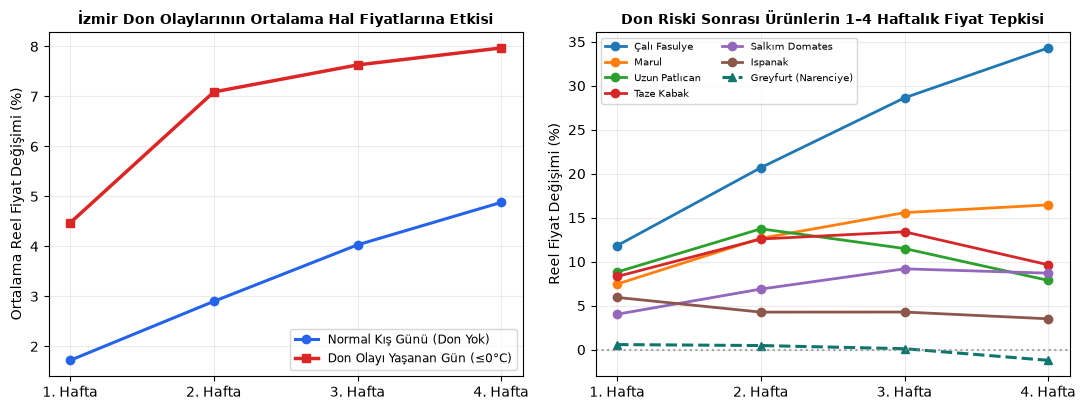


=== 12 ÖZELLİK vs 15 ÖZELLİK (İZMİR DON & SICAKLIK) MODEL KARŞILAŞTIRMASI ===
                                                Model  Özellik Sayısı  Genel Test MAE (TL)  Kış Dönemi MAE (TL)  Test R²
              Temel Model (12 Özellik - Sıcaklık Yok)              12                4.085                4.521   0.8826
Don Zenginleştirilmiş Model (15 Özellik - Open-Meteo)              15                4.102                4.505   0.8853
Don özellikli model kaydedildi: C:\Users\11\OneDrive\Desktop\G04_HalFiyat\03_Model\model_don_ozellikli.joblib


In [1]:
# Adım 14: İzmir Don Olaylarının Gecikmeli Fiyat Etkisi ve 15 Özellikli Don Modeli
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

for _aday in [Path.cwd()] + list(Path.cwd().parents):
    if (_aday / "01_Veri").exists() and (_aday / "03_Model").exists():
        PROJE_KOKU = _aday
        break
VERI_KLASORU = PROJE_KOKU / "01_Veri"
MODEL_KLASORU = PROJE_KOKU / "03_Model"
RAPOR_KLASORU = PROJE_KOKU / "04_Rapor"

df_don = pd.read_csv(VERI_KLASORU / "hal_reel_don_ozellikli.csv", low_memory=False)
df_don["TARIH"] = pd.to_datetime(df_don["TARIH"], errors="coerce")
df_don["MAL_TURU"] = df_don["MAL_TURU"].astype(str).str.strip().str.upper().apply(
    lambda s: "ITHAL" if s.replace("İ", "I").strip(".").startswith("ITHAL") else s.strip(".")
)
df_don["MAL_ADI"] = df_don["MAL_ADI"].astype(str).str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
df_don["BIRIM"] = df_don["BIRIM"].astype(str).str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
df_don = df_don.sort_values(["MAL_ADI", "BIRIM", "TARIH"]).reset_index(drop=True)
df_don["AY"] = df_don["TARIH"].dt.month
df_don["HAFTA"] = df_don["TARIH"].dt.isocalendar().week.astype(int)

# 14.1 Don Olaylarının 1, 2, 3 ve 4 Hafta Sonraki Gecikmeli Reel Fiyat Etkisi (Kış Ayları: Aralık-Mart)
for hafta_no in [1, 2, 3, 4]:
    kayit_adimi = hafta_no * 5  # ~5 hal iş günü = 1 takvim haftası
    df_don[f"ARTIS_{hafta_no}H_PCT"] = (
        (df_don.groupby(["MAL_ADI", "BIRIM"])["REEL_ORTALAMA_UCRET"].shift(-kayit_adimi) / df_don["REEL_ORTALAMA_UCRET"]) - 1.0
    ) * 100.0

kis_df = df_don[df_don["AY"].isin([12, 1, 2, 3])].copy()
genel_don_ozet = kis_df.groupby("DON_VAR_MI")[["ARTIS_1H_PCT", "ARTIS_2H_PCT", "ARTIS_3H_PCT", "ARTIS_4H_PCT"]].mean().round(2)
print("=== KIŞ AYLARINDA DON OLAYI (DON_VAR_MI) SONRASI ORTALAMA REEL FİYAT ARTIŞI (%) ===")
print(genel_don_ozet)

odak_urunler = ["FASULYE CALI", "MARUL", "PATLICAN UZUN", "KABAK TAZE", "DOMATES SALKIM", "ISPANAK", "CILEK", "GREYFURT"]
urun_tr_ad = {
    "FASULYE CALI": "Çalı Fasulye", "MARUL": "Marul", "PATLICAN UZUN": "Uzun Patlıcan",
    "KABAK TAZE": "Taze Kabak", "DOMATES SALKIM": "Salkım Domates", "ISPANAK": "Ispanak",
    "CILEK": "Çilek", "GREYFURT": "Greyfurt (Narenciye)",
}

urun_don_tablo = (
    kis_df[kis_df["HAFIF_DON_RISKI"] == 1]
    .groupby("MAL_ADI")[["ARTIS_1H_PCT", "ARTIS_2H_PCT", "ARTIS_3H_PCT", "ARTIS_4H_PCT"]]
    .mean()
    .round(2)
    .reindex(odak_urunler)
    .reset_index()
)
urun_don_tablo["Ürün Adı"] = urun_don_tablo["MAL_ADI"].map(urun_tr_ad)
urun_don_tablo["Zirve Etkisi Haftası"] = urun_don_tablo[["ARTIS_1H_PCT", "ARTIS_2H_PCT", "ARTIS_3H_PCT", "ARTIS_4H_PCT"]].idxmax(axis=1).map({
    "ARTIS_1H_PCT": "1. Hafta", "ARTIS_2H_PCT": "2. Hafta", "ARTIS_3H_PCT": "3. Hafta", "ARTIS_4H_PCT": "4. Hafta"
})
temiz_don_csv = urun_don_tablo.rename(columns={
    "ARTIS_1H_PCT": "1. Hafta Değişim (%)",
    "ARTIS_2H_PCT": "2. Hafta Değişim (%)",
    "ARTIS_3H_PCT": "3. Hafta Değişim (%)",
    "ARTIS_4H_PCT": "4. Hafta Değişim (%)",
})[["Ürün Adı", "1. Hafta Değişim (%)", "2. Hafta Değişim (%)", "3. Hafta Değişim (%)", "4. Hafta Değişim (%)", "Zirve Etkisi Haftası"]]

temiz_don_csv.to_csv(VERI_KLASORU / "don_etkisi_haftalik_analiz.csv", index=False, encoding="utf-8-sig")
print("\n=== ÜRÜN BAZLI DON RİSKİ SONRASI 1–4 HAFTA REEL FİYAT DEĞİŞİMİ (%) ===")
print(temiz_don_csv.to_string(index=False))

# Gecikmeli Don Etkisi Grafiği
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))
hafta_etiket = ["1. Hafta", "2. Hafta", "3. Hafta", "4. Hafta"]
axes[0].plot(hafta_etiket, genel_don_ozet.loc[0].values, marker="o", linewidth=2.2, color="#2563eb", label="Normal Kış Günü (Don Yok)")
axes[0].plot(hafta_etiket, genel_don_ozet.loc[1].values, marker="s", linewidth=2.5, color="#dc2626", label="Don Olayı Yaşanan Gün (≤0°C)")
axes[0].set_title("İzmir Don Olaylarının Ortalama Hal Fiyatlarına Etkisi", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Ortalama Reel Fiyat Değişimi (%)")
axes[0].legend(fontsize=8.5)
axes[0].grid(True, alpha=0.25)

for _, r in urun_don_tablo.head(6).iterrows():
    axes[1].plot(hafta_etiket, [r["ARTIS_1H_PCT"], r["ARTIS_2H_PCT"], r["ARTIS_3H_PCT"], r["ARTIS_4H_PCT"]], marker="o", linewidth=2, label=r["Ürün Adı"])
g_row = urun_don_tablo[urun_don_tablo["MAL_ADI"] == "GREYFURT"].iloc[0]
axes[1].plot(hafta_etiket, [g_row["ARTIS_1H_PCT"], g_row["ARTIS_2H_PCT"], g_row["ARTIS_3H_PCT"], g_row["ARTIS_4H_PCT"]], marker="^", linestyle="--", linewidth=2.2, color="#0f766e", label=g_row["Ürün Adı"])
axes[1].axhline(0, color="gray", linestyle=":", alpha=0.7)
axes[1].set_title("Don Riski Sonrası Ürünlerin 1–4 Haftalık Fiyat Tepkisi", fontsize=10, fontweight="bold")
axes[1].set_ylabel("Reel Fiyat Değişimi (%)")
axes[1].legend(fontsize=7.5, ncol=2, loc="upper left")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
fig.savefig(MODEL_KLASORU / "don_etkisi_analiz.png", dpi=130, bbox_inches="tight")
fig.savefig(RAPOR_KLASORU / "grafik_10_don_etkisi_gecikmeli_analiz.png", dpi=130, bbox_inches="tight")
plt.show()

# 14.2 12 Özellikli Temel Model vs. 15 Özellikli Don/Sıcaklık Zenginleştirilmiş Model Karşılaştırması
df_don["HEDEF"] = df_don.groupby(["MAL_ADI", "BIRIM"])["REEL_ORTALAMA_UCRET"].shift(-7)
kat_cols = ["MAL_ADI", "MAL_TURU", "BIRIM"]
say_12 = ["AY", "HAFTA", "REEL_ORTALAMA_UCRET", "REEL_LAG_1", "REEL_LAG_7", "REEL_LAG_30", "REEL_DEGISIM_YUZDE", "REEL_OYNAKLIK_7", "REEL_OYNAKLIK_30"]
don_cols = ["IZMIR_MIN_SICAKLIK_C", "DON_VAR_MI", "HAFIF_DON_RISKI"]
say_15 = say_12 + don_cols

df_d_clean = df_don.replace([np.inf, -np.inf], np.nan).dropna(subset=kat_cols + say_15 + ["HEDEF"]).sort_values("TARIH").reset_index(drop=True)
ayrim_idx = int(len(df_d_clean) * 0.80)
test_bas = df_d_clean.loc[ayrim_idx, "TARIH"]
tr_df = df_d_clean[df_d_clean["TARIH"] <= test_bas - pd.Timedelta(days=7)]
te_df = df_d_clean[df_d_clean["TARIH"] >= test_bas]

sonuclar_don = []
for etiket, say_list in [("Temel Model (12 Özellik - Sıcaklık Yok)", say_12), ("Don Zenginleştirilmiş Model (15 Özellik - Open-Meteo)", say_15)]:
    pre_d = ColumnTransformer([
        ("kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), kat_cols),
        ("say", StandardScaler(), say_list),
    ])
    pipe_d = Pipeline([("on", pre_d), ("m", HistGradientBoostingRegressor(max_iter=200, max_depth=8, learning_rate=0.06, random_state=42))])
    pipe_d.fit(tr_df[kat_cols + say_list], tr_df["HEDEF"])
    pred_te = pipe_d.predict(te_df[kat_cols + say_list])
    
    # Kış ve don günlerindeki test performansı
    kis_mask = te_df["AY"].isin([12, 1, 2, 3])
    sonuclar_don.append({
        "Model": etiket,
        "Özellik Sayısı": len(kat_cols + say_list),
        "Genel Test MAE (TL)": round(float(mean_absolute_error(te_df["HEDEF"], pred_te)), 3),
        "Kış Dönemi MAE (TL)": round(float(mean_absolute_error(te_df.loc[kis_mask, "HEDEF"], pred_te[kis_mask])), 3),
        "Test R²": round(float(r2_score(te_df["HEDEF"], pred_te)), 4),
    })
    if len(say_list) == len(say_15):
        pipe_full_don = Pipeline([("on", pre_d), ("m", HistGradientBoostingRegressor(max_iter=220, max_depth=8, learning_rate=0.06, random_state=42))])
        pipe_full_don.fit(df_d_clean[kat_cols + say_15], df_d_clean["HEDEF"])
        joblib.dump(pipe_full_don, MODEL_KLASORU / "model_don_ozellikli.joblib")

don_kars_df = pd.DataFrame(sonuclar_don)
don_kars_df.to_csv(VERI_KLASORU / "don_model_karsilastirma.csv", index=False, encoding="utf-8-sig")
print("\n=== 12 ÖZELLİK vs 15 ÖZELLİK (İZMİR DON & SICAKLIK) MODEL KARŞILAŞTIRMASI ===")
print(don_kars_df.to_string(index=False))
print("Don özellikli model kaydedildi:", MODEL_KLASORU / "model_don_ozellikli.joblib")